# Desafio 04 — Serviços de Computação em Nuvem para Machine Learning
**Projeto:** Asteroid Impact Intelligence · **Autor:** Bruno Soares Ferreira Ramos · **Instituição:** Ford Enter & SENAI CIMATEC · **Professora:** Auriane do Carmo Barbosa

Fluxo completo de ML em nuvem: coleta de dados oficiais → armazenamento → preparação → treino e avaliação → inferência (API) → monitoramento → evidências.

**Base de dados:** asteroides próximos da Terra (NEAs) reais, obtidos diretamente do catálogo oficial **NASA/JPL Small-Body Database (SBDB)** pela *SBDB Query API*. O alvo `pha` é a classificação **fornecida pela fonte oficial** (*Potentially Hazardous Asteroid*), convertida em 1 (PHA) e 0 (não PHA), sem nenhuma regra criada no projeto. O modelo faz **classificação de PHA a partir de elementos orbitais; não prevê colisão com a Terra, probabilidade de impacto ou dano**. Os dados são um *snapshot* coletado em uma data específica (registrada em UTC) e podem mudar conforme novas observações e atualizações do catálogo.

| Camada | Serviço usado | Equivalente AWS | Função |
|---|---|---|---|
| Desenvolvimento | Google Colab | SageMaker Studio / Notebook | Notebook gerenciado |
| Fonte de dados | JPL SBDB Query API | — | Catálogo oficial de asteroides |
| Armazenamento | Cloud Storage (versionado) | Amazon S3 | Dados, modelos, logs e relatórios |
| Treino / registro | scikit-learn + registro no bucket | SageMaker Training / Model Registry | Experimentos e versionamento |
| Inferência | API Flask (`/health`, `/predict`) | Endpoint SageMaker / API Gateway | Serviço de predição |
| Monitoramento | Logs JSON, alertas, drift | CloudWatch | Latência, erros e deriva |

**Modos (`USE_GCP`):** `False` (padrão) usa um bucket **emulado** em disco, com a mesma interface e versionamento; `True` usa o **Google Cloud Storage real** (exige projeto com faturamento). O modo usado fica registrado no manifesto final. Em ambos os modos a coleta dos dados vem da API real da NASA/JPL, então é necessário acesso à internet.

**Referência dos dados:** JET PROPULSION LABORATORY. *SBDB Query API*. Pasadena: California Institute of Technology, [2021]. Disponível em: https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html. Acesso em: 13 nov. 2026. Endpoint: https://ssd-api.jpl.nasa.gov/sbdb_query.api.

In [1]:
# No Google Colab, execute antes: %pip -q install flask joblib requests scikit-learn
import os, sys, json, time, shutil, threading, hashlib, zipfile, math
import importlib.metadata as package_metadata
from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor
import joblib, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from flask import Flask, request, jsonify
from werkzeug.serving import make_server
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, make_scorer,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve)
print("Python:", sys.version.split()[0], "| Ambiente: Jupyter / Google Colab (notebook gerenciado)")

Python: 3.12.3 | Ambiente: Jupyter / Google Colab (notebook gerenciado)


## 1. Configuração do ambiente e armazenamento (Ação 1 — Passos 1 a 3)
Altere `USE_GCP` para `True` **somente** em um Colab com projeto Google Cloud autorizado. Toda a pipeline acessa o armazenamento por `store` (`put`, `get`, `list`, `generations`), então trocar o bucket emulado pelo real não exige alterar o restante do código.

In [2]:
USE_GCP = False
GCP_PROJECT_ID = ''
GCP_REGION = 'us-central1'
BUCKET_NAME = (GCP_PROJECT_ID + '-asteroid-ml') if GCP_PROJECT_ID else 'asteroid-impact-ml-demo'
BASE_DIR, RANDOM_STATE = 'asteroid_impact_cloud_ml', 42
np.random.seed(RANDOM_STATE)

if USE_GCP:
    assert GCP_PROJECT_ID, 'Defina GCP_PROJECT_ID para usar a nuvem.'
    from google.colab import auth
    auth.authenticate_user()
for sub in ['data/raw', 'data/processed', 'models', 'logs', 'reports', 'figures', '_staging']:
    os.makedirs(os.path.join(BASE_DIR, sub), exist_ok=True)

class LocalObjectStore:
    kind = 'local-emulado'
    def __init__(self, bucket, root='cloud_emulado'):
        self.bucket, self.root = bucket, Path(root) / bucket
        self.root.mkdir(parents=True, exist_ok=True)
    def put(self, local_path, key):
        generation = time.time_ns()
        for dest in (self.root / key, self.root / '.generations' / f'{key}.{generation}'):
            dest.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(local_path, dest)
        return {'key': key, 'generation': generation, 'uri': f'emulated://{self.bucket}/{key}'}
    def get(self, key, local_path):
        Path(local_path).parent.mkdir(parents=True, exist_ok=True); shutil.copy2(self.root / key, local_path); return local_path
    def list(self, prefix=''):
        rel = (str(p.relative_to(self.root)) for p in self.root.rglob('*') if p.is_file() and '.generations' not in p.parts)
        return sorted(r for r in rel if r.startswith(prefix))
    def generations(self, key):
        return sorted(int(p.name.rsplit('.', 1)[1]) for p in (self.root / '.generations').glob(key + '.*'))

class GCSObjectStore:
    kind = 'google-cloud-storage'
    def __init__(self, project, bucket, location):
        from google.cloud import storage
        self.bucket_name, self.client = bucket, storage.Client(project=project)
        self.bucket = self.client.bucket(bucket)
        if not self.bucket.exists(): self.bucket = self.client.create_bucket(bucket, location=location)
        self.bucket.versioning_enabled = True; self.bucket.patch()
    def put(self, local_path, key):
        blob = self.bucket.blob(key); blob.upload_from_filename(local_path)
        return {'key': key, 'generation': int(blob.generation), 'uri': f'gs://{self.bucket_name}/{key}'}
    def get(self, key, local_path):
        Path(local_path).parent.mkdir(parents=True, exist_ok=True); self.bucket.blob(key).download_to_filename(local_path); return local_path
    def list(self, prefix=''): return sorted(b.name for b in self.client.list_blobs(self.bucket_name, prefix=prefix))
    def generations(self, key):
        return sorted(int(b.generation) for b in self.client.list_blobs(self.bucket_name, prefix=key, versions=True) if b.name == key)

store = GCSObjectStore(GCP_PROJECT_ID, BUCKET_NAME, GCP_REGION) if USE_GCP else LocalObjectStore(BUCKET_NAME)
upload_log = []
def publish(relpath):
    info = store.put(os.path.join(BASE_DIR, relpath), relpath); upload_log.append(info); return info

print('Modo:', 'NUVEM (Google Cloud)' if USE_GCP else 'EMULADO (bucket local)', '| Bucket:', BUCKET_NAME, '| Serviço:', store.kind)

Modo: EMULADO (bucket local) | Bucket: asteroid-impact-ml-demo | Serviço: local-emulado


## 2. Coleta, armazenamento e preparação dos dados (Ação 2 — Passos 4 e 5)
**Fonte:** JPL Small-Body Database, *SBDB Query API* (https://ssd-api.jpl.nasa.gov/sbdb_query.api; documentação em https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html). A consulta usa os filtros `sb-kind=a` (asteroides) e `sb-group=neo` (objetos próximos da Terra), com paginação (`limit` e `limit-from`), ordenação por `spkid` e precisão total (`full-prec`). Cada registro é um asteroide real catalogado.

- **Alvo:** `pha` oficial (`Y` → 1, `N` → 0). Nenhum rótulo é criado ou substituído.
- **Atributos do modelo:** `e`, `a`, `i`, `om`, `w`, `ma`, `q`, `per` (elementos orbitais).
- **Mantidos só para auditoria:** `spkid`, `full_name`, `pdes`, `class`, `neo`, `moid`, `H`, `epoch`, `orbit_id`, `condition_code`, `data_arc`, `n_obs_used`. `moid` e `H` **não entram no treino de propósito**: pelo critério oficial, PHA é um NEA com MOID ≤ 0,05 au e H ≤ 22, então usá-los vazaria o rótulo para o modelo.
- Como `H` fica de fora, o modelo não vê o tamanho do objeto e é esperado que ele não reproduza o rótulo perfeitamente.
- O CSV bruto guarda exatamente o que a API devolveu; a limpeza ocorre na preparação e cada remoção é registrada em `reports/dataset_version.json`.
- Se a API estiver indisponível, a coleta é **interrompida com erro**. Não há dataset alternativo nem dados artificiais.

In [3]:
SBDB_URL = 'https://ssd-api.jpl.nasa.gov/sbdb_query.api'
SBDB_DOC = 'https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html'
SBDB_FILTERS = {'sb-kind': 'a', 'sb-group': 'neo'}
SBDB_FIELDS = ['spkid', 'full_name', 'pdes', 'class', 'neo', 'pha',                       # identificação e classificação
               'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'per',                                # elementos orbitais
               'moid', 'H', 'epoch', 'orbit_id', 'condition_code', 'data_arc', 'n_obs_used']  # auditoria
FEATURES = ['e', 'a', 'i', 'om', 'w', 'ma', 'q', 'per']   # sem moid/H: evita vazamento do rótulo
target_names = {0: 'não PHA', 1: 'PHA'}
PAGE_SIZE, MAX_RETRIES, TIMEOUT = 10000, 5, (10, 120)

def sbdb_get(params):
    """GET na SBDB Query API com timeout e novas tentativas (espera exponencial) para falhas temporárias."""
    last_error = None
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            r = requests.get(SBDB_URL, params=params, timeout=TIMEOUT, headers={'User-Agent': 'asteroid-impact-intelligence/1.0 (educacional)'})
            if r.status_code == 200:
                try: return r.json()
                except ValueError as e: raise RuntimeError(f'Resposta da API não é um JSON válido: {r.text[:200]!r}') from e
            if r.status_code not in (429, 500, 502, 503, 504):
                raise RuntimeError(f'A API recusou a requisição (HTTP {r.status_code}): {r.text[:300]}')
            last_error = f'HTTP {r.status_code}'
        except (requests.ConnectionError, requests.Timeout) as e:
            last_error = type(e).__name__
        if attempt < MAX_RETRIES:
            print(f'  tentativa {attempt}/{MAX_RETRIES} falhou ({last_error}); nova tentativa em {2 ** attempt}s')
            time.sleep(2 ** attempt)
    raise RuntimeError(f'API JPL/SBDB indisponível após {MAX_RETRIES} tentativas (último erro: {last_error}). '
                       'Coleta interrompida: nenhum dado alternativo ou sintético será usado. Tente novamente mais tarde.')

def collect_sbdb_neas():
    """Coleta todos os NEAs do SBDB. As páginas (limit/limit-from) são pedidas em paralelo, pois o total é conhecido de antemão."""
    collected_at = datetime.now(timezone.utc)
    meta = sbdb_get(dict(SBDB_FILTERS))                       # sem 'fields', a API devolve apenas a contagem
    total = int(meta.get('count', 0))
    if total <= 0: raise RuntimeError(f'A API não informou registros para os filtros {SBDB_FILTERS}: {meta}')
    query = {**SBDB_FILTERS, 'fields': ','.join(SBDB_FIELDS), 'full-prec': 'true', 'sort': 'spkid'}
    def fetch_page(offset):
        page = sbdb_get({**query, 'limit': PAGE_SIZE, 'limit-from': offset})
        if page.get('fields') != SBDB_FIELDS or not isinstance(page.get('data'), list):
            raise RuntimeError(f"Estrutura inesperada na resposta da API (campos recebidos: {page.get('fields')}).")
        if any(len(r) != len(SBDB_FIELDS) for r in page['data']): raise RuntimeError('Registro com número de campos diferente do solicitado.')
        print(f'  página a partir de {offset}: {len(page["data"])} registros'); return page['data']
    with ThreadPoolExecutor(max_workers=3) as pool:           # poucos pedidos simultâneos, por cortesia com a API
        pages = list(pool.map(fetch_page, range(0, total, PAGE_SIZE)))
    rows = [r for page in pages for r in page]
    if len(rows) != total: print(f'AVISO: a API informou {total} registros, mas {len(rows)} foram recebidos (o catálogo pode ter mudado durante a coleta).')
    info = {'mode': 'nova coleta na API', 'collected_at_utc': collected_at.isoformat(), 'api_signature': meta.get('signature'), 'api_reported_count': total,
            'query_parameters': {**query, 'limit': PAGE_SIZE, 'limit-from': f'0, {PAGE_SIZE}, ... (paginação)'}}
    return pd.DataFrame(rows, columns=SBDB_FIELDS), info

raw_rel = 'data/raw/neo_orbital_snapshot.csv'
REUSE_SNAPSHOT = False   # True: reutiliza o snapshot já guardado no bucket (não consulta a API); False: nova coleta na NASA/JPL
if REUSE_SNAPSHOT and raw_rel in store.list('data/raw/') and 'reports/dataset_version.json' in store.list('reports/'):
    prev = json.loads(Path(store.get('reports/dataset_version.json', os.path.join(BASE_DIR, '_staging/prev_version.json'))).read_text(encoding='utf-8'))
    raw_df = pd.read_csv(store.get(raw_rel, os.path.join(BASE_DIR, raw_rel)), dtype=str, keep_default_na=False, na_values=[''])
    collection_info = {'mode': 'snapshot reutilizado do bucket', **{k: prev[k] for k in ('collected_at_utc', 'api_reported_count', 'query_parameters')}, 'api_signature': prev['source']['api_signature']}
    print('Reutilizando o snapshot da coleta de', collection_info['collected_at_utc'])
else:
    print('Consultando', SBDB_URL, SBDB_FILTERS)
    raw_df, collection_info = collect_sbdb_neas()
    raw_df.to_csv(os.path.join(BASE_DIR, raw_rel), index=False)
raw_info = publish(raw_rel)
print('Registros:', len(raw_df), '| Coletado em (UTC):', collection_info['collected_at_utc'], '| Modo:', collection_info['mode'], '| Objeto:', raw_info['uri'])

Consultando https://ssd-api.jpl.nasa.gov/sbdb_query.api {'sb-kind': 'a', 'sb-group': 'neo'}


  página a partir de 10000: 10000 registros
  página a partir de 20000: 10000 registros
  página a partir de 0: 10000 registros


  página a partir de 40000: 3068 registros
  página a partir de 30000: 10000 registros


Registros: 43068 | Coletado em (UTC): 2026-11-13T10:24:36.927607+00:00 | Modo: nova coleta na API | Objeto: emulated://asteroid-impact-ml-demo/data/raw/neo_orbital_snapshot.csv


In [4]:
staged_raw = store.get(raw_rel, os.path.join(BASE_DIR, '_staging/raw.csv'))
df = pd.read_csv(staged_raw, dtype=str, keep_default_na=False, na_values=[''])      # tudo como texto: nada é alterado na leitura
n_raw, removed = len(df), {}

def remove(mask, reason):
    global df
    removed[reason] = int(mask.sum()); df = df[~mask]

remove(df['spkid'].isna(), 'spkid ausente')
remove(df.duplicated('spkid', keep='first'), 'spkid duplicado')
remove(df['neo'] != 'Y', 'objeto não marcado como NEO (neo != Y)')
remove(~df['pha'].isin(['Y', 'N']), 'rótulo pha ausente ou inválido')
numeric = df[FEATURES].apply(pd.to_numeric, errors='coerce')
remove(~np.isfinite(numeric).all(axis=1), 'atributo orbital ausente ou não numérico')
df = df.assign(**{c: numeric[c] for c in FEATURES})
df['pha'] = (df['pha'] == 'Y').astype(int)                                          # PHA = 1, não PHA = 0 (rótulo oficial)

class_counts = df['pha'].value_counts().to_dict()
if set(class_counts) != {0, 1} or min(class_counts.values()) < 10:
    raise RuntimeError(f'Treinamento impossível: as duas classes precisam ter ao menos 10 registros. Distribuição obtida: {class_counts}')

X, y = df[FEATURES], df['pha']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=RANDOM_STATE, stratify=y)
for name, Xs, ys in [('train', X_train, y_train), ('test', X_test, y_test)]:
    Xs.assign(pha=ys.values, spkid=df.loc[Xs.index, 'spkid'].values).to_csv(os.path.join(BASE_DIR, f'data/processed/{name}.csv'), index=False)
    publish(f'data/processed/{name}.csv')

raw_sha256 = hashlib.sha256(Path(staged_raw).read_bytes()).hexdigest()
dataset_version = {
    'dataset': 'NASA/JPL SBDB — asteroides próximos da Terra (NEAs), snapshot oficial',
    'snapshot_id': f"sbdb_neo_{collection_info['collected_at_utc'][:19].replace('-', '').replace(':', '')}Z_{raw_sha256[:12]}",
    'source': {'name': 'NASA/JPL Small-Body Database (SBDB) — SBDB Query API', 'api_url': SBDB_URL, 'documentation': SBDB_DOC,
               'api_signature': collection_info['api_signature']},
    'query_parameters': collection_info['query_parameters'], 'fields_requested': SBDB_FIELDS,
    'collection_mode': collection_info['mode'], 'collected_at_utc': collection_info['collected_at_utc'], 'api_reported_count': collection_info['api_reported_count'],
    'records_obtained': n_raw, 'records_removed': removed, 'records_after_preparation': len(df),
    'class_distribution': {'raw_pha_labels': {('ausente' if pd.isna(k) else str(k)): int(v) for k, v in raw_df['pha'].value_counts(dropna=False).items()},
                           'prepared': {target_names[k]: int(v) for k, v in sorted(class_counts.items())},
                           'train': {target_names[k]: int(v) for k, v in y_train.value_counts().sort_index().items()},
                           'test': {target_names[k]: int(v) for k, v in y_test.value_counts().sort_index().items()}},
    'target': 'pha (rótulo oficial do SBDB: Y=1, N=0)', 'features': FEATURES,
    'features_excluded_on_purpose': {'moid': 'define PHA (vazamento de rótulo)', 'H': 'define PHA (vazamento de rótulo)',
                                     'spkid/full_name/pdes': 'identificadores', 'class/neo': 'categóricos / constante pelo filtro'},
    'raw_file': raw_rel, 'raw_sha256': raw_sha256, 'raw_generation': raw_info['generation'],
    'train_rows': len(X_train), 'test_rows': len(X_test), 'split': {'test_size': .2, 'stratify': True, 'random_state': RANDOM_STATE},
    'note': 'Snapshot do catálogo em uma data específica; resultados podem mudar com novas observações e atualizações do SBDB.'}
Path(BASE_DIR, 'reports/dataset_version.json').write_text(json.dumps(dataset_version, indent=2, ensure_ascii=False), encoding='utf-8'); publish('reports/dataset_version.json')
print('Removidos:', removed, '| Após preparação:', len(df), '| Classes:', dataset_version['class_distribution']['prepared'])
print('Treino:', X_train.shape, '| Teste:', X_test.shape, '| Snapshot:', dataset_version['snapshot_id'])

Removidos: {'spkid ausente': 0, 'spkid duplicado': 0, 'objeto não marcado como NEO (neo != Y)': 0, 'rótulo pha ausente ou inválido': 135, 'atributo orbital ausente ou não numérico': 0} | Após preparação: 42933 | Classes: {'não PHA': 40381, 'PHA': 2552}
Treino: (34346, 8) | Teste: (8587, 8) | Snapshot: sbdb_neo_20261113T102436Z_6be8fec3173f


## 3. Treinamento, avaliação e registro do modelo (Ação 2 — Passo 6)
Três algoritmos (regressão logística, Random Forest e Gradient Boosting em sua versão por histogramas, bem mais rápida com dezenas de milhares de registros) são comparados por **validação cruzada estratificada de 5 folds no treino**, com os folds executados em paralelo. O F1 da classe `PHA` orienta a seleção (classe rara não deve ser avaliada só por acurácia). **v1** é o *baseline* (regressão logística); **v2** é o melhor dos demais; o **champion** é a versão com maior F1 em validação. O teste só é usado depois da seleção, para a avaliação final. Modelos e metadados são registrados e versionados no bucket.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'precision_pha': make_scorer(precision_score, zero_division=0),
           'recall_pha': make_scorer(recall_score, zero_division=0), 'f1_pha': make_scorer(f1_score, zero_division=0), 'roc_auc': 'roc_auc'}
def make_pipe(clf): return Pipeline([('scaler', StandardScaler()), ('classifier', clf)])
candidates = {'Regressão Logística': make_pipe(LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)),
              'Random Forest': make_pipe(RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RANDOM_STATE)),
              'Gradient Boosting (Hist)': make_pipe(HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE))}

rows = []
for name, est in candidates.items():
    t0 = time.time(); s = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({'experimento': name, 'tempo_cv_s': round(time.time() - t0, 2),
                 **{f'cv_{m}_media': float(s[f'test_{m}'].mean()) for m in scoring}, **{f'cv_{m}_dp': float(s[f'test_{m}'].std()) for m in scoring}})
exp_df = pd.DataFrame(rows); exp_df.to_csv(os.path.join(BASE_DIR, 'reports/experiments.csv'), index=False); publish('reports/experiments.csv')
print(exp_df[['experimento', 'cv_accuracy_media', 'cv_recall_pha_media', 'cv_f1_pha_media', 'cv_roc_auc_media']].round(4).to_string(index=False))

             experimento  cv_accuracy_media  cv_recall_pha_media  cv_f1_pha_media  cv_roc_auc_media
     Regressão Logística             0.7311               0.6352           0.2195            0.7571
           Random Forest             0.9331               0.1626           0.2233            0.8315
Gradient Boosting (Hist)             0.7875               0.7253           0.2888            0.8500


Versões: {'v1': 'Regressão Logística', 'v2': 'Gradient Boosting (Hist)'} | Champion: v2
v1 {'accuracy': 0.7238, 'precision_pha': 0.1294, 'recall_pha': 0.6373, 'f1_pha': 0.2151, 'roc_auc_pha': 0.7637, 'training_seconds': 0.0904, 'test_rows': 8587}
v2 {'accuracy': 0.7607, 'precision_pha': 0.1643, 'recall_pha': 0.7412, 'f1_pha': 0.2689, 'roc_auc_pha': 0.8415, 'training_seconds': 1.6068, 'test_rows': 8587}


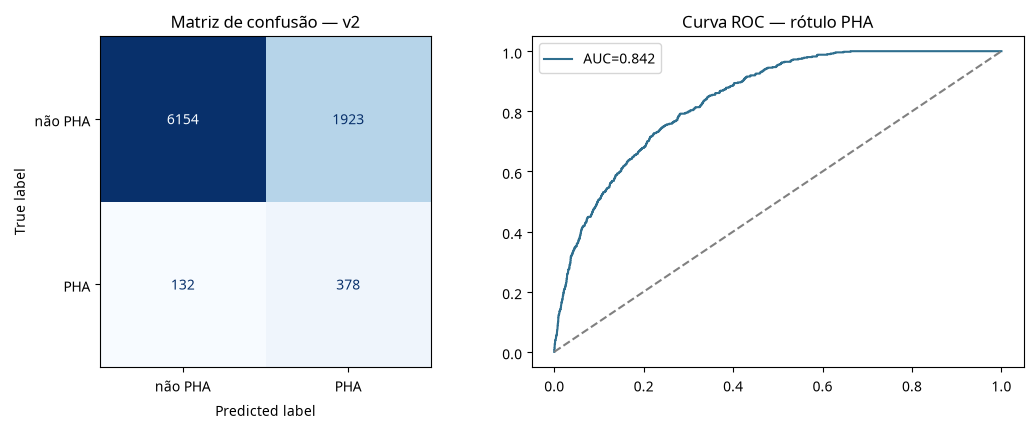

              precision    recall  f1-score   support

     não PHA       0.98      0.76      0.86      8077
         PHA       0.16      0.74      0.27       510

    accuracy                           0.76      8587
   macro avg       0.57      0.75      0.56      8587
weighted avg       0.93      0.76      0.82      8587



In [6]:
baseline_name = 'Regressão Logística'
v2_name = exp_df[exp_df.experimento != baseline_name].sort_values('cv_f1_pha_media', ascending=False).iloc[0].experimento

versions = {}
for version, name in [('v1', baseline_name), ('v2', v2_name)]:
    model = clone(candidates[name]); t0 = time.time(); model.fit(X_train, y_train)
    pred, proba = model.predict(X_test), model.predict_proba(X_test)[:, 1]
    test = {'accuracy': accuracy_score(y_test, pred), 'precision_pha': precision_score(y_test, pred, zero_division=0),
            'recall_pha': recall_score(y_test, pred, zero_division=0), 'f1_pha': f1_score(y_test, pred, zero_division=0),
            'roc_auc_pha': roc_auc_score(y_test, proba), 'training_seconds': time.time() - t0, 'test_rows': len(y_test)}
    versions[version] = {'name': name, 'model': model, 'pred': pred, 'proba': proba, 'test': test, 'cv': exp_df[exp_df.experimento == name].iloc[0].to_dict()}
champion = max(versions, key=lambda v: versions[v]['cv']['cv_f1_pha_media'])
print('Versões:', {v: versions[v]['name'] for v in versions}, '| Champion:', champion)
for v in versions: print(v, {k: round(x, 4) for k, x in versions[v]['test'].items()})

champ = versions[champion]; cm = confusion_matrix(y_test, champ['pred']); fpr, tpr, _ = roc_curve(y_test, champ['proba'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ConfusionMatrixDisplay(cm, display_labels=['não PHA', 'PHA']).plot(ax=axes[0], cmap='Blues', colorbar=False); axes[0].set_title(f'Matriz de confusão — {champion}')
axes[1].plot(fpr, tpr, color='#2f6f8f', label=f"AUC={champ['test']['roc_auc_pha']:.3f}"); axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set_title('Curva ROC — rótulo PHA'); axes[1].legend(); fig.tight_layout()
fig.savefig(os.path.join(BASE_DIR, 'figures/evaluation_champion.png'), dpi=150); publish('figures/evaluation_champion.png'); plt.show()
report_text = classification_report(y_test, champ['pred'], target_names=['não PHA', 'PHA'])
Path(BASE_DIR, 'reports/classification_report_champion.txt').write_text(report_text, encoding='utf-8'); publish('reports/classification_report_champion.txt'); print(report_text)

In [7]:
registry = {'champion': champion, 'updated_at_utc': datetime.now(timezone.utc).isoformat(), 'versions': {}}
for version, info in versions.items():
    vdir = os.path.join(BASE_DIR, 'models', version); os.makedirs(vdir, exist_ok=True)
    model_file = os.path.join(vdir, 'model.joblib'); joblib.dump(info['model'], model_file)
    metadata = {'model_version': version, 'algorithm': info['name'], 'estimator': str(info['model'].named_steps['classifier']),
                'dataset_sha256': dataset_version['raw_sha256'], 'features': FEATURES, 'random_state': RANDOM_STATE,
                'sklearn_version': package_metadata.version('scikit-learn'),
                'metrics_cv': {k: v for k, v in info['cv'].items() if k.startswith('cv_')}, 'metrics_test': info['test'],
                'model_sha256': hashlib.sha256(Path(model_file).read_bytes()).hexdigest(),
                'stage': 'champion' if version == champion else 'archived', 'created_at_utc': datetime.now(timezone.utc).isoformat()}
    Path(vdir, 'metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
    obj = publish(f'models/{version}/model.joblib'); publish(f'models/{version}/metadata.json')
    registry['versions'][version] = {'algorithm': info['name'], 'stage': metadata['stage'], 'model_sha256': metadata['model_sha256'], 'generation': obj['generation']}
Path(BASE_DIR, 'models/registry.json').write_text(json.dumps(registry, indent=2, ensure_ascii=False), encoding='utf-8'); publish('models/registry.json')
Path(BASE_DIR, 'reports/metrics.json').write_text(json.dumps({'champion': champion, 'versions': {v: versions[v]['test'] for v in versions}, 'confusion_matrix_champion': cm.tolist()}, indent=2), encoding='utf-8'); publish('reports/metrics.json')
print(json.dumps(registry, indent=2))

{
  "champion": "v2",
  "updated_at_utc": "2026-11-13T10:24:58.307891+00:00",
  "versions": {
    "v1": {
      "algorithm": "Regress\u00e3o Log\u00edstica",
      "stage": "archived",
      "model_sha256": "3854295271f127e1b90fa569e5824ef78ba02351d5a42b2cb9b61f180af6e924",
      "generation": 1794565498311686884
    },
    "v2": {
      "algorithm": "Gradient Boosting (Hist)",
      "stage": "champion",
      "model_sha256": "d5d1ecfb4bc78cd0223c03876ad72bc6cc8b75b40171688b9de9c6c71db9c5aa",
      "generation": 1794565498324222414
    }
  }
}


## 4. Serviço de inferência e testes de funcionamento (Ação 2 — Passo 7)
A API carrega o **champion a partir do registro no bucket**, expõe `GET /health` e `POST /predict` e grava um log JSON por requisição (status, latência e versão do modelo), sem armazenar os valores orbitais. Roda em `127.0.0.1:5000`.

In [8]:
LOG_PATH = os.path.join(BASE_DIR, 'logs/inference_logs.jsonl'); Path(LOG_PATH).write_text('', encoding='utf-8')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'); log_lock = threading.Lock()
CHAMPION = json.loads(Path(store.get('models/registry.json', os.path.join(BASE_DIR, '_staging/registry.json'))).read_text())['champion']
api_model = joblib.load(store.get(f'models/{CHAMPION}/model.joblib', os.path.join(BASE_DIR, '_staging/champion.joblib')))

def log_request(status, started, error_type=None):
    rec = {'run_id': RUN_ID, 'timestamp_utc': datetime.now(timezone.utc).isoformat(), 'endpoint': '/predict', 'status_code': status,
           'latency_ms': round((time.perf_counter() - started) * 1000, 3), 'model_version': CHAMPION,
           'synthetic_test': request.headers.get('X-Synthetic-Test'), 'error_type': error_type}
    with log_lock, open(LOG_PATH, 'a', encoding='utf-8') as f: f.write(json.dumps(rec) + '\n')

app = Flask('asteroid_model_api')
@app.get('/health')
def health(): return jsonify({'status': 'ok', 'model_version': CHAMPION, 'run_id': RUN_ID})

@app.post('/predict')
def predict():
    started = time.perf_counter(); payload = request.get_json(silent=True)
    try:
        values = payload.get('features') if isinstance(payload, dict) else None
        if not isinstance(values, dict): raise ValueError("O corpo deve conter um objeto 'features'.")
        missing, extra = sorted(set(FEATURES) - set(values)), sorted(set(values) - set(FEATURES))
        if missing or extra: raise ValueError(f'Features inválidas; ausentes={len(missing)}, extras={extra}.')
        row = [float(values[k]) for k in FEATURES]
        if not all(math.isfinite(x) for x in row): raise ValueError('As features precisam ser numéricas finitas.')
        proba = float(api_model.predict_proba(pd.DataFrame([row], columns=FEATURES))[0, 1]); pred = int(proba >= .5)
        log_request(200, started)
        return jsonify({'prediction': pred, 'label': target_names[pred], 'probability_pha': proba, 'model_version': CHAMPION})
    except (ValueError, TypeError) as e:
        log_request(400, started, type(e).__name__); return jsonify({'error': str(e)}), 400
    except Exception as e:
        log_request(500, started, type(e).__name__); return jsonify({'error': 'Falha interna de inferência.'}), 500

if 'api_thread' not in globals() or not api_thread.is_alive():
    api_server = make_server('127.0.0.1', 5000, app, threaded=True)
    api_thread = threading.Thread(target=api_server.serve_forever, daemon=True); api_thread.start(); time.sleep(.5)
print('API local ativa em http://127.0.0.1:5000 | modelo:', CHAMPION)

API local ativa em http://127.0.0.1:5000 | modelo: v2


In [9]:
BASE_URL = 'http://127.0.0.1:5000'
h = requests.get(f'{BASE_URL}/health', timeout=5); assert h.status_code == 200; print('GET /health:', h.status_code, h.json())

functional_tests = []
for i in range(6):
    r = requests.post(f'{BASE_URL}/predict', json={'features': X_test.iloc[i].to_dict()}, timeout=5); assert r.status_code == 200; b = r.json()
    functional_tests.append({'caso': i + 1, 'http': r.status_code, 'label_api': b['label'], 'label_real': target_names[int(y_test.iloc[i])], 'p_pha': round(b['probability_pha'], 4)})
print(pd.DataFrame(functional_tests).to_string(index=False))

H = {'X-Synthetic-Test': 'validation'}
validation_tests = {'features_ausentes': requests.post(f'{BASE_URL}/predict', json={'features': {'e': .1}}, headers=H).status_code,
                    'feature_extra': requests.post(f'{BASE_URL}/predict', json={'features': {**X_test.iloc[0].to_dict(), 'inesperada': 9}}, headers=H).status_code}
assert all(v == 400 for v in validation_tests.values()); print('Validações:', validation_tests)

127.0.0.1 - - [13/Nov/2026 10:24:58] "GET /health HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:58] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:58] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 400 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 400 -


GET /health: 200 {'model_version': 'v2', 'run_id': '20261113T102458_339820Z', 'status': 'ok'}
 caso  http label_api label_real  p_pha
    1   200       PHA    não PHA 0.5100
    2   200       PHA    não PHA 0.7852
    3   200   não PHA    não PHA 0.0031
    4   200       PHA    não PHA 0.6957
    5   200   não PHA    não PHA 0.4503
    6   200   não PHA    não PHA 0.0732
Validações: {'features_ausentes': 400, 'feature_extra': 400}


## 5. Monitoramento e escalabilidade (Ação 3 — Passo 8)
Teste de carga com **300 requisições e 8 clientes concorrentes** (latência e vazão), resumo do log estruturado da execução, regras de alerta (equivalentes a políticas do CloudWatch/Cloud Monitoring) e verificação de **data drift** (PSI, limite 0,2) e **model drift** (queda de desempenho) sobre um lote simulado.

In [10]:
N_REQUESTS, N_WORKERS = 300, 8
payloads = [{'features': X_test.iloc[i % len(X_test)].to_dict()} for i in range(N_REQUESTS)]
def one_call(p):
    t = time.perf_counter(); r = requests.post(f'{BASE_URL}/predict', json=p, headers={'X-Synthetic-Test': 'load'}, timeout=10)
    return r.status_code, (time.perf_counter() - t) * 1000
start = time.perf_counter()
with ThreadPoolExecutor(max_workers=N_WORKERS) as pool: results = list(pool.map(one_call, payloads))
wall = time.perf_counter() - start; lat = np.array([r[1] for r in results]); codes = [r[0] for r in results]
load_test = {'requests': N_REQUESTS, 'concurrent_clients': N_WORKERS, 'http_200': codes.count(200), 'http_errors': N_REQUESTS - codes.count(200),
             'duration_s': round(wall, 3), 'throughput_rps': round(N_REQUESTS / wall, 1),
             'latency_ms': {f'p{q}': float(np.percentile(lat, q)) for q in (50, 95, 99)}, 'scope': 'loopback; não mede rede nem autoscaling'}
Path(BASE_DIR, 'reports/load_test.json').write_text(json.dumps(load_test, indent=2), encoding='utf-8'); publish('reports/load_test.json'); print(json.dumps(load_test, indent=2))

127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:24:59] "POST /predict HTTP/1.1" 200 -


... (291 outputs left out)

127.0.0.1 - - [13/Nov/2026 10:25:01] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:25:01] "POST /predict HTTP/1.1" 200 -


127.0.0.1 - - [13/Nov/2026 10:25:01] "POST /predict HTTP/1.1" 200 -


{
  "requests": 300,
  "concurrent_clients": 8,
  "http_200": 300,
  "http_errors": 0,
  "duration_s": 2.306,
  "throughput_rps": 130.1,
  "latency_ms": {
    "p50": 59.45014999998932,
    "p95": 79.83753355000974,
    "p99": 93.95422286999707
  },
  "scope": "loopback; n\u00e3o mede rede nem autoscaling"
}


In [11]:
logs = [json.loads(x) for x in open(LOG_PATH, encoding='utf-8') if x.strip()]
ok = [r for r in logs if r['status_code'] == 200]; errors = [r for r in logs if r['status_code'] != 200]
expected = [r for r in errors if r['synthetic_test'] == 'validation']; unexpected = [r for r in errors if r['synthetic_test'] != 'validation']
server_lat = np.array([r['latency_ms'] for r in ok])
monitoring = {'run_id': RUN_ID, 'model_version': CHAMPION, 'total_requests': len(logs), 'successful_requests': len(ok), 'error_requests': len(errors),
              'expected_validation_errors': len(expected), 'unexpected_error_requests': len(unexpected), 'error_rate_unexpected': len(unexpected) / len(logs),
              'server_latency_ms': {f'p{q}': float(np.percentile(server_lat, q)) for q in (50, 95, 99)}, 'scope': 'somente esta execução'}
alerts = [{'regra': 'taxa de erros inesperados <= 1%', 'status': 'OK' if monitoring['error_rate_unexpected'] <= .01 else 'ALERTA'},
          {'regra': 'latência p95 no cliente <= 500 ms', 'status': 'OK' if load_test['latency_ms']['p95'] <= 500 else 'ALERTA'},
          {'regra': 'nenhuma resposta HTTP 5xx', 'status': 'OK' if not any(r['status_code'] >= 500 for r in logs) else 'ALERTA'}]
for fname, obj in [('monitoring_summary', monitoring), ('alerts', alerts)]:
    Path(BASE_DIR, f'reports/{fname}.json').write_text(json.dumps(obj, indent=2), encoding='utf-8'); publish(f'reports/{fname}.json')
publish('logs/inference_logs.jsonl'); print(pd.DataFrame(alerts).to_string(index=False))

                            regra status
  taxa de erros inesperados <= 1%     OK
latência p95 no cliente <= 500 ms     OK
        nenhuma resposta HTTP 5xx     OK


In [12]:
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None); c = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

shifted = X_test.copy(); shifted['e'] = np.clip(shifted['e'] * 1.35, 0, 0.95); shifted['q'] = shifted['q'] * .82   # simulação explícita, não tráfego real
drift_df = pd.DataFrame([{'cenario': sc, 'feature': f, 'psi': psi(X_train[f].values, b[f].values), 'drift_psi': psi(X_train[f].values, b[f].values) > .2}
                         for sc, b in [('holdout', X_test), ('lote simulado', shifted)] for f in FEATURES])
drift_df.to_csv(os.path.join(BASE_DIR, 'reports/drift_report.csv'), index=False); publish('reports/drift_report.csv')

def perf(batch):
    pred = api_model.predict(batch); return {'accuracy': accuracy_score(y_test, pred), 'recall_pha': recall_score(y_test, pred, zero_division=0)}
perf_hold, perf_shift = perf(X_test), perf(shifted)
drift_summary = {'threshold_psi': .2, 'features_drifted_shifted': int(drift_df[(drift_df.cenario == 'lote simulado') & drift_df.drift_psi].shape[0]),
                 'performance_holdout': perf_hold, 'performance_shifted': perf_shift, 'accuracy_drop_pp': (perf_hold['accuracy'] - perf_shift['accuracy']) * 100}
drift_summary['retraining_recommended'] = bool(drift_summary['features_drifted_shifted'] >= 2 or drift_summary['accuracy_drop_pp'] > 5)
Path(BASE_DIR, 'reports/drift_summary.json').write_text(json.dumps(drift_summary, indent=2), encoding='utf-8'); publish('reports/drift_summary.json'); print(json.dumps(drift_summary, indent=2))

{
  "threshold_psi": 0.2,
  "features_drifted_shifted": 2,
  "performance_holdout": {
    "accuracy": 0.7606847560265517,
    "recall_pha": 0.7411764705882353
  },
  "performance_shifted": {
    "accuracy": 0.5009898684057296,
    "recall_pha": 0.8019607843137255
  },
  "accuracy_drop_pp": 25.969488762082214,
  "retraining_recommended": true
}


## 6. Governança e evidências (Ação 3 — Passo 9)
O manifesto lista cada artefato com tamanho e SHA-256, o modo de execução e a trilha de objetos enviados ao bucket. O ZIP de evidências é validado e enviado ao bucket. Em Colab, baixe o ZIP antes de encerrar o runtime.

In [13]:
manifest_items = []
for sub in ['data', 'models', 'logs', 'reports', 'figures']:
    for root, _, files in os.walk(os.path.join(BASE_DIR, sub)):
        for name in sorted(files):
            full = os.path.join(root, name)
            if name != 'evidence_manifest.json':
                manifest_items.append({'path': os.path.relpath(full, BASE_DIR), 'bytes': os.path.getsize(full), 'sha256': hashlib.sha256(Path(full).read_bytes()).hexdigest()})
manifest = {'run_id': RUN_ID, 'created_at_utc': datetime.now(timezone.utc).isoformat(),
            'execution_mode': 'nuvem (Google Cloud Storage)' if USE_GCP else 'emulado (bucket local)', 'storage_service': store.kind, 'bucket': BUCKET_NAME,
            'champion_model': CHAMPION, 'dataset_sha256': dataset_version['raw_sha256'], 'dataset_snapshot_id': dataset_version['snapshot_id'],
            'data_source': dataset_version['source']['api_url'], 'dataset_collected_at_utc': dataset_version['collected_at_utc'], 'bucket_objects_uploaded': len(upload_log),
            'bucket_objects': store.list(''), 'artifacts': manifest_items}
manifest_path = os.path.join(BASE_DIR, 'reports/evidence_manifest.json'); Path(manifest_path).write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')

bundle_path = os.path.join(BASE_DIR, 'evidence_bundle.zip')
with zipfile.ZipFile(bundle_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for item in manifest_items: z.write(os.path.join(BASE_DIR, item['path']), arcname=item['path'])
    z.write(manifest_path, arcname='reports/evidence_manifest.json')
assert zipfile.ZipFile(bundle_path).testzip() is None
store.put(bundle_path, 'evidence/evidence_bundle.zip')
print('Modo:', manifest['execution_mode'], '| Artefatos:', len(manifest_items), '| SHA-256 ZIP:', hashlib.sha256(Path(bundle_path).read_bytes()).hexdigest())

Modo: emulado (bucket local) | Artefatos: 19 | SHA-256 ZIP: d6ba6f4b5a7d5bb4efaf9c5c9c3781720bbb8113eee2da40aa9c938092e071b5
